# Python Installation & Environment Setup

This lesson prepares your computer for the whole course. You install Python, a tool that manages Python versions and packages, and Jupyter, the notebook interface for every lesson.

**After this lesson you can:**

1. Install Python and the **uv** package manager.
2. Create an isolated environment for a project.
3. Start Jupyter and select the correct kernel.
4. Check the environment from inside a notebook.

All tools in this lesson are free and open source.

## 1. The Tools and Why We Use Them

| Tool | What it does | Why this course uses it |
| :--- | :--- | :--- |
| **Python** | The programming language and its interpreter | Every lesson except M05/M06 (R) |
| **uv** | Installs Python versions, creates environments, installs packages | Fast, one tool, reproducible with a lock file |
| **Jupyter** | Runs notebooks: code, text and output in one document | Every lesson is a notebook |
| **Miniforge** *(optional)* | The free conda distribution from the conda-forge community | Useful when a package exists only on conda-forge |

An **environment** is a folder that contains one Python interpreter and one set of packages. Each project has its own environment. Then a package upgrade in one project cannot break another project.

> **Note on Anaconda:** the Anaconda Distribution is free only for individuals and small organisations. Its terms changed in 2024. This course uses uv (and optionally Miniforge), which are free for everyone.

## 2. Install uv and Python

1. Install uv. Use **one** of these commands:

```bash
# macOS / Linux
curl -LsSf https://astral.sh/uv/install.sh | sh

# Windows (PowerShell)
powershell -ExecutionPolicy ByPass -c "irm https://astral.sh/uv/install.ps1 | iex"

# any system that already has Python
pip install uv
```

2. Check the installation:

```bash
uv --version
```

3. Install a Python version. uv downloads it into its own folder. It does not change the Python of your operating system.

```bash
uv python install 3.12
uv python list          # shows installed and available versions
```

## 3. Create the Course Environment

The repository has a `pyproject.toml` file. This file lists the packages for each module group. The `uv.lock` file pins the exact version of every package, so all learners get the same environment.

1. Go to the repository folder.
2. Create the environment and install the base packages:

```bash
uv sync
```

3. Add the group for the module that you study. For M01–M04, add `foundations`:

```bash
uv sync --group foundations
```

uv creates the environment in the `.venv` folder. You do not need to activate it if you start programs with `uv run`.

**For your own projects**, start a new project like this:

```bash
uv init my-project
cd my-project
uv add pandas matplotlib     # adds the packages to pyproject.toml and uv.lock
uv run python main.py
```

## 4. Start Jupyter

```bash
uv run jupyter lab
```

Jupyter opens in your browser. Open a notebook, then select the kernel **Python 3 (ipykernel)**. A **kernel** is the process that runs the code of a notebook. The kernel must come from the course environment; otherwise the packages are missing.

In **VS Code**, install the *Python* and *Jupyter* extensions. Open a notebook and click **Select Kernel** in the top-right corner. Select the interpreter in `.venv`.

## 5. Check the Environment From the Notebook

Run the cell below. It shows which Python runs this notebook and which packages are available.

In [1]:
import importlib.metadata as metadata
import platform
import shutil
import sys

print(f"Python version : {platform.python_version()}")
from pathlib import Path
exe = Path(sys.executable)
print(f"Interpreter    : .../{exe.parent.parent.name}/{exe.parent.name}/{exe.name}")   # last parts only
print(f"Operating sys. : {platform.system()} {platform.release()}")
print(f"In a venv      : {sys.prefix != sys.base_prefix}")
print(f"uv on PATH     : {shutil.which('uv') is not None}")

packages = ["numpy", "pandas", "matplotlib", "jupyterlab", "pytest", "pydantic", "ruff"]
print("\nPackage versions:")
for name in packages:
    try:
        print(f"  {name:<11} {metadata.version(name)}")
    except metadata.PackageNotFoundError:
        print(f"  {name:<11} not installed (run: uv sync --group foundations)")

Python version : 3.12.16
Interpreter    : .../.venv/bin/python
Operating sys. : Linux 6.6.87.2-microsoft-standard-WSL2
In a venv      : True
uv on PATH     : True

Package versions:
  numpy       2.5.5
  pandas      3.1.1
  matplotlib  3.11.2
  jupyterlab  4.6.6
  pytest      9.2.0
  pydantic    2.14.3
  ruff        0.17.5


`In a venv: True` means that the notebook runs inside an isolated environment. If a package shows "not installed", run the command in brackets and restart the kernel.

## 6. Python Versions and Their Support Period

Each Python version receives bug fixes and security fixes for about five years. After that date (the **end of life**), it receives no fixes. Use a version that is supported. The data below comes from the official release schedule on python.org.

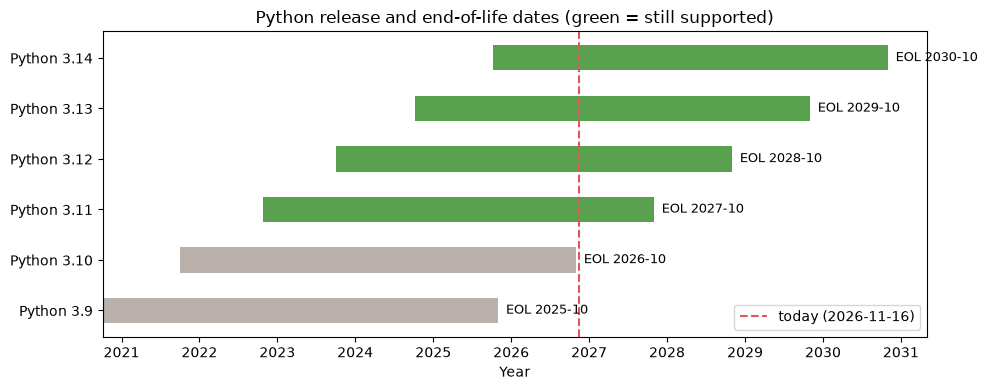

Supported versions today: 3.11, 3.12, 3.13, 3.14
This notebook runs Python 3.12.16


In [2]:
from datetime import date

import matplotlib.pyplot as plt

releases = {   # version: (release date, end of life)
    "3.9":  (date(2020, 10, 5),  date(2025, 10, 31)),
    "3.10": (date(2021, 10, 4),  date(2026, 10, 31)),
    "3.11": (date(2022, 10, 24), date(2027, 10, 31)),
    "3.12": (date(2023, 10, 2),  date(2028, 10, 31)),
    "3.13": (date(2024, 10, 7),  date(2029, 10, 31)),
    "3.14": (date(2025, 10, 7),  date(2030, 10, 31)),
}
today = date.today()

fig, ax = plt.subplots(figsize=(10, 4))
for row, (version, (start, end)) in enumerate(releases.items()):
    color = "#59A14F" if end > today else "#BAB0AC"
    ax.barh(row, (end - start).days, left=start, color=color, height=0.5)
    ax.text(end, row, f"  EOL {end:%Y-%m}", va="center", fontsize=9)
ax.axvline(today, color="#E15759", linestyle="--", label=f"today ({today:%Y-%m-%d})")
ax.set_yticks(range(len(releases)), [f"Python {v}" for v in releases])
ax.set_title("Python release and end-of-life dates (green = still supported)")
ax.set_xlabel("Year")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

supported = [v for v, (_, end) in releases.items() if end > today]
print(f"Supported versions today: {', '.join(supported)}")
print(f"This notebook runs Python {platform.python_version()}")

*Insight: Keep one environment per project and pin the versions in a lock file. "It works on my machine" problems almost always come from a different Python version or a different package version.*

## Real-World Use Case or Analogy

An environment is like a **separate toolbox for each job**. A carpenter keeps fine tools for furniture in one box and heavy tools for building work in another box. If one box gets a new hammer, the other box does not change.

In companies, every service has its own environment and lock file. A continuous integration (CI) server creates the environment from the lock file and runs the tests. Because the lock file pins every version, the server, the developers and the production system run exactly the same code.